# 01 Data analyse en data cleaning

**Workshops:** LU2 `01_DataAnalysis` (missende waarden, duplicaten, datatypes, schalen, plots) en vorig jaar
`01 Univariate`, `02 Distributions` en `03 Bivariate analyses`.

**Doel:** de dataset van de opdrachtgever (Lectoraat Digitale Didactiek, Curio) begrijpen, de kwaliteitsproblemen
vinden en een schone dataset maken waar we een model op kunnen trainen.

De dataset heeft drie sheets:

| Sheet | Inhoud |
| --- | --- |
| Leesmateriaal | 283 boeken, artikelen, blogposts, dichtbundels, kranten en tijdschriften |
| Studenten | 100 (gesimuleerde) studentprofielen met leesniveau, interesses en voorkeuren |
| Interacties | 2000 interacties: bekeken, gelezen, geliket, opgeslagen, niet afgemaakt, afgewezen |

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from reading_coach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Ruwe data inlezen
We lezen het leesmateriaal als tekst in, zodat pandas niets stilletjes omzet (bijvoorbeeld `'26.7%'`).

In [2]:
from reading_coach.data_cleaning import load_raw

raw = load_raw()
materials_raw, students_raw, interactions_raw = raw["materials"], raw["students"], raw["interactions"]
for name, frame in raw.items():
    print(f"{name:13s} {frame.shape}")
materials_raw.head()

materials     (283, 33)
students      (100, 9)
interactions  (2000, 8)


,Titel,Auteur,Korte omschrijving,Unnamed: 3,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,taal,aantal_paginas,geschatte_leestijd_min,bron_url,doelgroep,gegevensstatus,woordenaantal_omschrijving,gem_woordlengte,gem_zinslengte_woorden,aandeel_lange_woorden_pct,aantal_zinnen,leescomplexiteit_score,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,Het dagboek van Anne Frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,NaN,boek,3F,WOII;onderduik,LM-0001,fictie,WOII,WOII; onderduik,Nederlands,265.0,556.0,NaN,MBO,Aangevuld (deels gesimuleerd),30,23.48,NaN,26.7%,2,NaN,VERHALEN,Educatief Media,2025,PDF,CAT-00001,B1,Hoog,NaN,fictie,3.4
1,Blauw Water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,NaN,Boek,3F,spanning;stalking,LM-0002,fictie,spanning,spanning; stalking,Nederlands,171.0,184.0,NaN,MBO,Aangevuld (deels gesimuleerd),28,5.54,14.0,28.6,2,48.8,verhalen,Leeswereld,2005,Digitaal,CAT-00002,B2,hoog,NT2,fictie,2.5
2,Boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",NaN,Boek,2F,liefde;relaties,LM-0003,fictie,liefde,liefde; relaties,Nederlands,219.0,662.0,NaN,MBO/NT2,Aangevuld (deels gesimuleerd),23,6.35,11.5,34.8,2,49.2,verhalen,NaN,2025,Digitaal,CAT-00003,B2,Midden,NT2,fictie,3.8
3,Cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,NaN,Boek,3F,ontmoeting;verbondenheid,LM-0004,fictie,ontmoeting,ontmoeting; verbondenheid,Nederlands,288.0,748.0,NaN,MBO,Aangevuld (deels gesimuleerd),23,7.35,11.5,43.5,2,55.3,verhalen,Uitgeverij Noord,2018,Digitaal,CAT-00004,batch-2,Laag,NT2,fictie,3.9
4,De biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,NaN,Boek,2F,geheimen;schuld,LM-0005,fictie,geheimen,geheimen; schuld,Nederlands,358.0,196.0,NaN,MBO/NT2,Aangevuld (deels gesimuleerd),21,6.48,10.5,38.1,2,49.2,verhalen,Uitgeverij Noord,NaN,online,CAT-00005,B3,Laag,MBO/NT2,fictie,3.1


## 2. Missende waarden
Welke kolommen zijn (deels) leeg? Een kolom die helemaal leeg is kan weg, bij andere kolommen kiezen we per kolom een strategie.

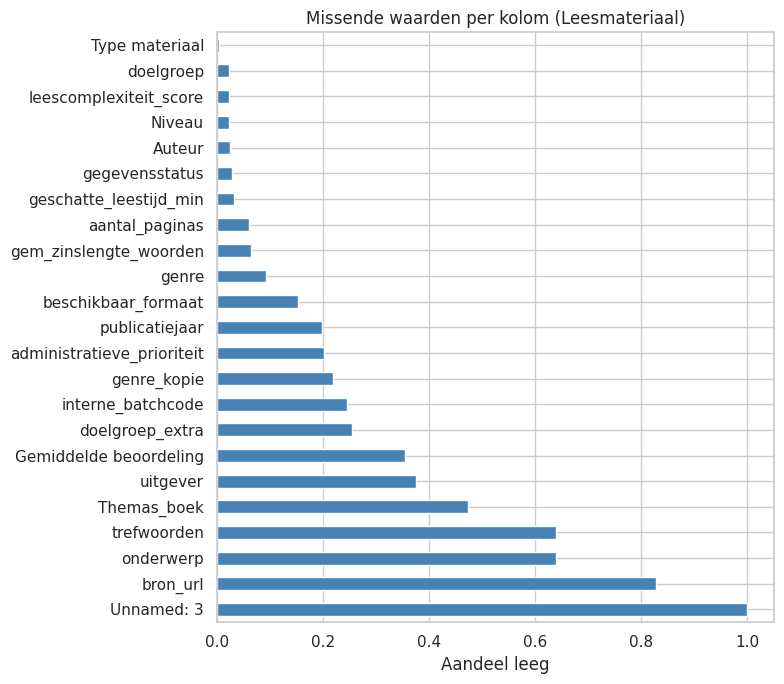

,Unnamed: 3,bron_url,onderwerp,trefwoorden,Themas_boek,uitgever,Gemiddelde beoordeling,doelgroep_extra,interne_batchcode,genre_kopie,administratieve_prioriteit,publicatiejaar,beschikbaar_formaat,genre,gem_zinslengte_woorden,aantal_paginas,geschatte_leestijd_min,gegevensstatus,Auteur,Niveau,leescomplexiteit_score,doelgroep,Type materiaal,Titel,Korte omschrijving,taal,materiaal_id,interessecluster,aandeel_lange_woorden_pct,woordenaantal_omschrijving,aantal_zinnen,gem_woordlengte,cataloguscode
aandeel_leeg,1.0,0.83,0.64,0.64,0.47,0.37,0.35,0.25,0.24,0.22,0.2,0.2,0.15,0.09,0.06,0.06,0.03,0.03,0.02,0.02,0.02,0.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
missing = materials_raw.isna().mean().sort_values(ascending=False)
ax = missing[missing > 0].plot.barh(figsize=(8, 7), color="steelblue")
ax.set_xlabel("Aandeel leeg")
ax.set_title("Missende waarden per kolom (Leesmateriaal)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "01_missing_values.png", dpi=120)
plt.show()
missing.round(2).to_frame("aandeel_leeg").T

## 3. Inconsistente categorieën
Dezelfde waarde wordt op verschillende manieren geschreven. Dat zou een model als aparte categorieën zien.

In [4]:
for column in ["Type materiaal", "Niveau", "taal", "doelgroep", "interessecluster", "beschikbaar_formaat", "administratieve_prioriteit"]:
    print(f"{column}: {materials_raw[column].value_counts(dropna=False).to_dict()}")

Type materiaal: {'Boek': 140, 'Boek - thriller': 37, 'online artikel': 34, 'Boek - roman': 28, 'dichtbundel': 23, 'blogpost': 15, 'tijdschrift': 2, 'boek': 1, 'digitale krant': 1, 'krant (papier)': 1, nan: 1}
Niveau: {'2F': 135, '3F': 89, '3F+': 30, '2F-3F': 23, nan: 6}
taal: {'Nederlands': 271, 'NL': 5, 'NED': 4, 'nederlands': 3}
doelgroep: {'MBO/NT2': 154, 'MBO': 110, 'mbo': 6, nan: 6, 'NT2': 5, 'mbo / nt2': 2}
interessecluster: {'verhalen': 255, 'VERHALEN': 13, 'maatschappij': 13, 'vrije tijd': 2}
beschikbaar_formaat: {'Papier': 66, 'PDF': 54, nan: 43, 'online': 39, 'Digitaal': 38, 'papier': 30, 'Online': 13}
administratieve_prioriteit: {'Laag': 71, nan: 57, 'Hoog': 53, 'hoog': 52, 'Midden': 50}


## 4. Getallen die tekst zijn en onmogelijke waarden

In [5]:
from reading_coach.data_cleaning import to_number

numeric = pd.DataFrame({
    column: to_number(materials_raw[column])
    for column in ["aantal_paginas", "geschatte_leestijd_min", "gem_woordlengte", "aandeel_lange_woorden_pct",
                   "leescomplexiteit_score", "publicatiejaar", "Gemiddelde beoordeling"]
})
print("Voorbeelden van tekstwaarden:", materials_raw["aandeel_lange_woorden_pct"].str.contains("%").sum(), "keer een %-teken,",
      (materials_raw["publicatiejaar"] == "onbekend").sum(), "keer 'onbekend' als jaartal")
numeric.describe().T

Voorbeelden van tekstwaarden: 16 keer een %-teken, 10 keer 'onbekend' als jaartal


,count,mean,std,min,25%,50%,75%,max
aantal_paginas,266.0,177.31203,115.814639,-3.0,107.0,178.5,264.0,400.0
geschatte_leestijd_min,274.0,377.343066,263.985609,5.0,171.0,366.0,587.5,946.0
gem_woordlengte,283.0,7.217244,3.972142,4.33,5.73,6.35,7.595,54.0
aandeel_lange_woorden_pct,283.0,42.430035,21.840599,0.0,28.6,35.0,50.0,100.0
leescomplexiteit_score,277.0,45.813718,12.202466,14.9,36.6,45.4,52.2,80.2
publicatiejaar,217.0,2018.225806,17.169894,1998.0,2013.0,2018.0,2023.0,2099.0
Gemiddelde beoordeling,183.0,3.27377,0.352963,2.2,3.0,3.3,3.5,4.0


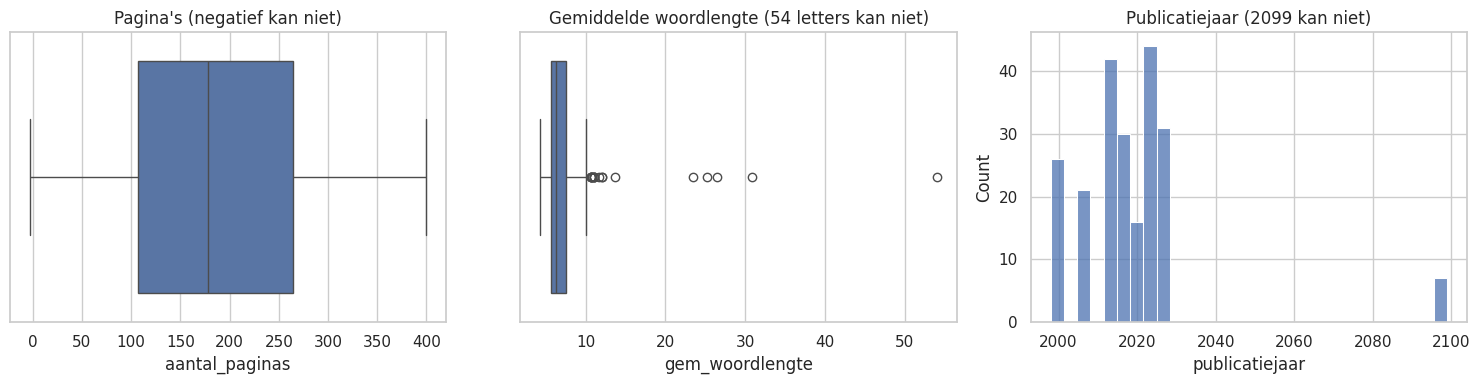

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=numeric["aantal_paginas"], ax=axes[0]).set_title("Pagina's (negatief kan niet)")
sns.boxplot(x=numeric["gem_woordlengte"], ax=axes[1]).set_title("Gemiddelde woordlengte (54 letters kan niet)")
sns.histplot(numeric["publicatiejaar"], ax=axes[2], bins=30).set_title("Publicatiejaar (2099 kan niet)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "01_outliers.png", dpi=120)
plt.show()

## 5. Duplicaten
`materiaal_id` lijkt een sleutel, maar is het niet. Ook staan sommige artikelen er twee keer in (een keer als *online artikel* en een keer als *blogpost*, met dezelfde url).

In [7]:
print("Dubbele materiaal_id:", materials_raw["materiaal_id"].duplicated().sum())
print("Dubbele cataloguscode:", materials_raw["cataloguscode"].duplicated().sum())
duplicate_titles = materials_raw[materials_raw["Titel"].duplicated(keep=False)].sort_values("Titel")
duplicate_titles[["Titel", "Auteur", "Type materiaal", "cataloguscode", "bron_url"]]

Dubbele materiaal_id: 4
Dubbele cataloguscode: 0


,Titel,Auteur,Type materiaal,cataloguscode,bron_url
147,Gaat AI een rol spelen in de rechtspraak?,KIJK-redactie,online artikel,CAT-00148,https://www.kijkmagazine.nl/artikel/robotrecht...
177,Gaat AI een rol spelen in de rechtspraak?,KIJK Magazine,blogpost,CAT-00178,https://www.kijkmagazine.nl/artikel/robotrecht...
152,Nieuwe stap bij vernieuwing van curriculum,Rijksoverheid,online artikel,CAT-00153,https://www.rijksoverheid.nl/actueel/nieuws/20...
182,Nieuwe stap bij vernieuwing van curriculum,Rijksoverheid,blogpost,CAT-00183,https://www.rijksoverheid.nl/actueel/nieuws/20...
140,Transparantie-eisen voor AI: wat betekent dit ...,Autoriteit Persoonsgegevens,online artikel,CAT-00141,https://www.autoriteitpersoonsgegevens.nl/them...
176,Transparantie-eisen voor AI: wat betekent dit ...,Autoriteit Persoonsgegevens,blogpost,CAT-00177,https://www.autoriteitpersoonsgegevens.nl/them...
139,Vanaf 2 augustus wordt duidelijker of het AI i...,Autoriteit Persoonsgegevens (redactie),online artikel,CAT-00140,https://www.autoriteitpersoonsgegevens.nl/actu...
174,Vanaf 2 augustus wordt duidelijker of het AI i...,Autoriteit Persoonsgegevens,blogpost,CAT-00175,https://www.autoriteitpersoonsgegevens.nl/actu...
143,Wat is een rechtsstaat?,ProDemos,online artikel,CAT-00144,https://prodemos.nl/kennis/informatie-over-pol...
175,Wat is een rechtsstaat?,ProDemos,blogpost,CAT-00176,https://prodemos.nl/kennis/informatie-over-pol...


## 6. Opschonen

Alle stappen staan in `src/reading_coach/data_cleaning.py`, zodat het model en de API precies dezelfde cleaning gebruiken.
De ruwe kolommen hebben Nederlandse namen; die hernoem ik daar één keer naar het Engels, zodat de rest van de code Engels is.
Hieronder het verslag van wat er is aangepast. Mijn keuzes:

* **Verwijderd:** lege kolom `Unnamed: 3` en administratieve kolommen (`interne_batchcode`, `administratieve_prioriteit`,
  `gegevensstatus`, `uitgever`). Die zeggen niets over leesplezier en minder data is ook beter voor privacy (dataminimalisatie).
* **Gelijkgetrokken:** type materiaal, taal, doelgroep en hoofdletters. De types staan niet in de code: welke er zijn en
  hoe ze heten haal ik uit de waarden in de data zelf. Komt er ooit een podcast bij, dan is dat gewoon een nieuw type.
* **Verkeerde kolom:** bij artikelen, blogs en gedichten staat in de omschrijving een lijstje thema's en in de themakolom
  een url. Dat herken ik aan de waarden zelf (een url, of een korte opsomming met komma's) en zet ik in de goede kolom.
* **Omgezet:** `'26.7%'` naar 26.7, `'onbekend'` naar leeg.
* **Onmogelijk gemaakt leeg:** pagina's kleiner of gelijk aan 0, woordlengte boven 15, jaartal in de toekomst.
* **Aangevuld (imputatie):** pagina's en leestijd met de mediaan per type, niveau op basis van de leescomplexiteit,
  genre uit de kopie kolom of het meest voorkomende genre van hetzelfde type. Met een vlag, zodat ik weet wat geschat is.
* **Samengevoegd:** thema's uit vier kolommen, dubbele materialen (interacties wijzen naar het overgebleven materiaal).
* **Geleerd uit de data:** hoe positief elk soort interactie is. Bij *geliket* hoort gemiddeld een 5, bij *afgewezen*
  een 2. Interactietypes met een gemiddelde van 3,5 of hoger tellen als positief.

In [8]:
from reading_coach.data_cleaning import clean_all, save_processed

data = clean_all()
save_processed(data)
materials, students, interactions = data.materials, data.students, data.interactions
data.report.to_frame()

,step,what
0,1,Dropped administrative or empty columns: Unnam...
1,2,10 spellings of the material type brought back...
2,3,"Genre filled from genre_copy, then from the mo..."
3,4,"Language spellings merged (Nederlands), target..."
4,5,"Numbers converted ('26.7%', 'onbekend'), impos..."
5,6,Pages and reading time filled with the median ...
6,7,6 missing levels estimated from the complexity...
7,8,69 rows with themes in the description column ...
8,9,"Themes merged from book_themes, keywords, subj..."
9,10,"8 duplicate materials (same url, or same title..."


In [9]:
print(materials.shape, students.shape, interactions.shape)
print("Nog leeg na cleaning:")
print(materials.isna().sum()[lambda s: s > 0])
materials.head()

(275, 32) (100, 11) (1986, 11)
Nog leeg na cleaning:
author                7
subgenre            210
format               42
description          61
source_url          234
publication_year     73
avg_rating          100
dtype: int64


,catalog_code,material_id,key,title,author,type,type_label,subgenre,genre,level,level_num,language,target_group,format,interest_cluster,themes,description,text,source_url,pages,reading_minutes,publication_year,avg_rating,description_words,avg_word_length,avg_sentence_length,long_words_pct,sentence_count,complexity_score,pages_imputed,minutes_imputed,level_imputed
0,CAT-00001,LM-0001,het dagboek van anne frank|anne frank|boek,Het dagboek van Anne Frank,Anne Frank,boek,boek,None,fictie,3F,3.0,Nederlands,MBO,pdf,verhalen,woii;onderduik,Dagboek van een Joods meisje dat tijdens de Tw...,Het dagboek van Anne Frank. Dagboek van een Jo...,None,265.0,556.0,2025,3.4,30,6.33,15.0,26.7,2,46.4,False,False,False
1,CAT-00002,LM-0002,blauw water|s van der vlugt|boek,Blauw Water,S. van der Vlugt,boek,boek,None,fictie,3F,3.0,Nederlands,MBO,digitaal,verhalen,spanning;stalking,Spannende thriller waarin een vrouw wordt geco...,Blauw Water. Spannende thriller waarin een vro...,None,171.0,184.0,2005,2.5,28,5.54,14.0,28.6,2,48.8,False,False,False
2,CAT-00003,LM-0003,boer vindt vrouw|h van der werf|boek,Boer vindt vrouw,H. van der Werf,boek,boek,None,fictie,2F,2.0,Nederlands,MBO/NT2,digitaal,verhalen,liefde;relaties,"Toegankelijk verhaal over liefde, relaties en ...",Boer vindt vrouw. Toegankelijk verhaal over li...,None,219.0,662.0,2025,3.8,23,6.35,11.5,34.8,2,49.2,False,False,False
3,CAT-00004,LM-0004,cadeau voor u|harry mulisch|boek,Cadeau voor u!,Harry Mulisch,boek,boek,None,fictie,3F,3.0,Nederlands,MBO,digitaal,verhalen,ontmoeting;verbondenheid,Bundel toegankelijke verhalen over verrassende...,Cadeau voor u!. Bundel toegankelijke verhalen ...,None,288.0,748.0,2018,3.9,23,7.35,11.5,43.5,2,55.3,False,False,False
4,CAT-00005,LM-0005,de biecht|mickey roorda|boek,De biecht,Mickey Roorda,boek,boek,None,fictie,2F,2.0,Nederlands,MBO/NT2,online,verhalen,geheimen;schuld,Verhaal waarin verborgen geheimen en persoonli...,De biecht. Verhaal waarin verborgen geheimen e...,None,358.0,196.0,<NA>,3.1,21,6.48,10.5,38.1,2,49.2,False,False,False


## 7. Univariate analyse (vorig jaar workshop 01 en 02)

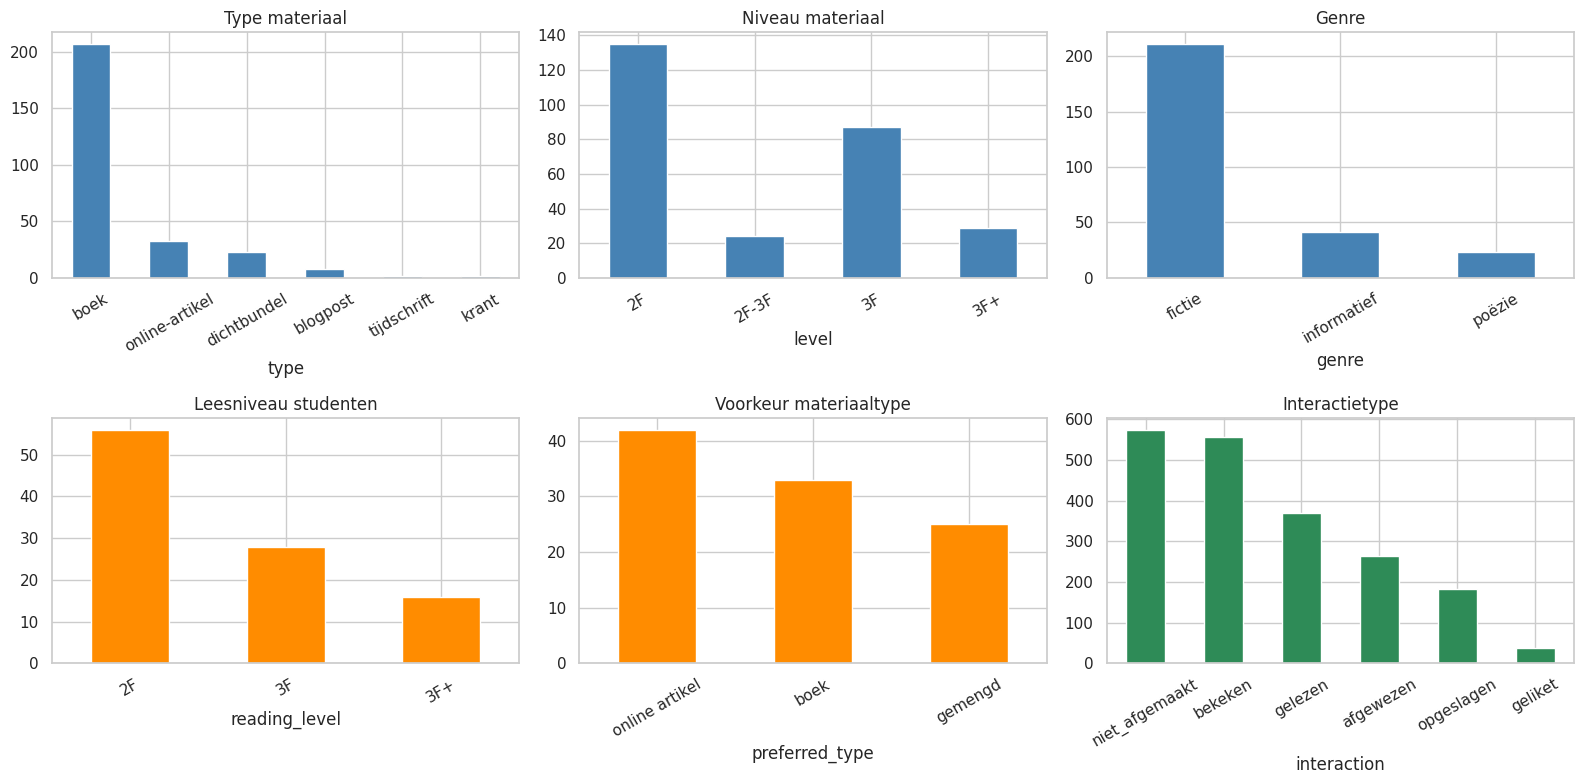

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
materials["type"].value_counts().plot.bar(ax=axes[0, 0], title="Type materiaal", color="steelblue")
materials["level"].value_counts().reindex(["2F", "2F-3F", "3F", "3F+"]).plot.bar(ax=axes[0, 1], title="Niveau materiaal", color="steelblue")
materials["genre"].value_counts().plot.bar(ax=axes[0, 2], title="Genre", color="steelblue")
students["reading_level"].value_counts().reindex(["2F", "3F", "3F+"]).plot.bar(ax=axes[1, 0], title="Leesniveau studenten", color="darkorange")
students["preferred_type"].value_counts().plot.bar(ax=axes[1, 1], title="Voorkeur materiaaltype", color="darkorange")
interactions["interaction"].value_counts().plot.bar(ax=axes[1, 2], title="Interactietype", color="seagreen")
for ax in axes.ravel():
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "01_distributions.png", dpi=120)
plt.show()

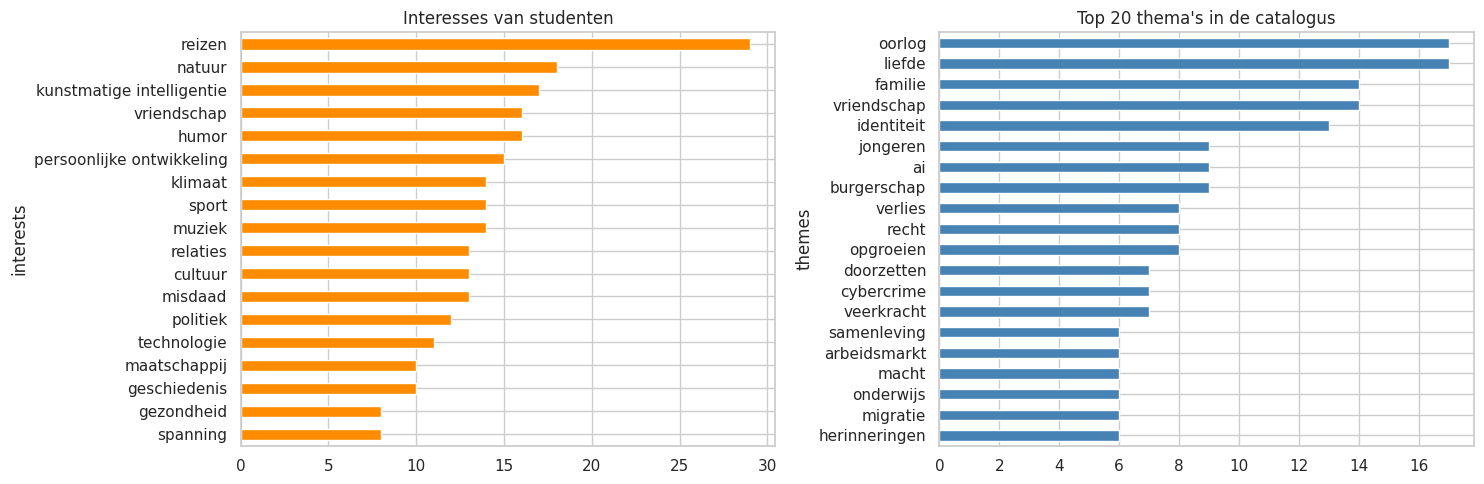

In [11]:
interests = students["interests"].str.split(";").explode().value_counts()
themes = materials["themes"].str.split(";").explode().replace("", np.nan).dropna().value_counts().head(20)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
interests.plot.barh(ax=axes[0], title="Interesses van studenten", color="darkorange").invert_yaxis()
themes.plot.barh(ax=axes[1], title="Top 20 thema's in de catalogus", color="steelblue").invert_yaxis()
plt.tight_layout()
plt.show()

**Wat valt op?** Studenten noemen interesses als *reizen*, *kunstmatige intelligentie*, *sport* en *muziek*, terwijl de
catalogus vooral fictie bevat met thema's als *liefde*, *oorlog* en *vriendschap*. De woorden sluiten niet één op één aan.
Daarom breid ik interesses later uit met thema's die in de catalogus vaak samen voorkomen met die interesse, en gebruik ik
NLP (notebook 03). Een vaste lijst met synoniemen gebruik ik bewust niet: die moet je bij elk nieuw boek bijwerken.

## 8. Betrouwbaarheidsinterval (vorig jaar workshop 02)
Hoe zeker zijn we van het aandeel positieve interacties?

In [12]:
from scipy import stats

share = interactions["positive"].mean()
n = len(interactions)
low, high = stats.binom.interval(0.95, n, share)
print(f"Aandeel positief: {share:.3f}, 95% interval: {low / n:.3f} tot {high / n:.3f}")

Aandeel positief: 0.298, 95% interval: 0.278 tot 0.318


## 9. Bivariate analyse: wat hangt samen met een positieve interactie? (vorig jaar workshop 03)

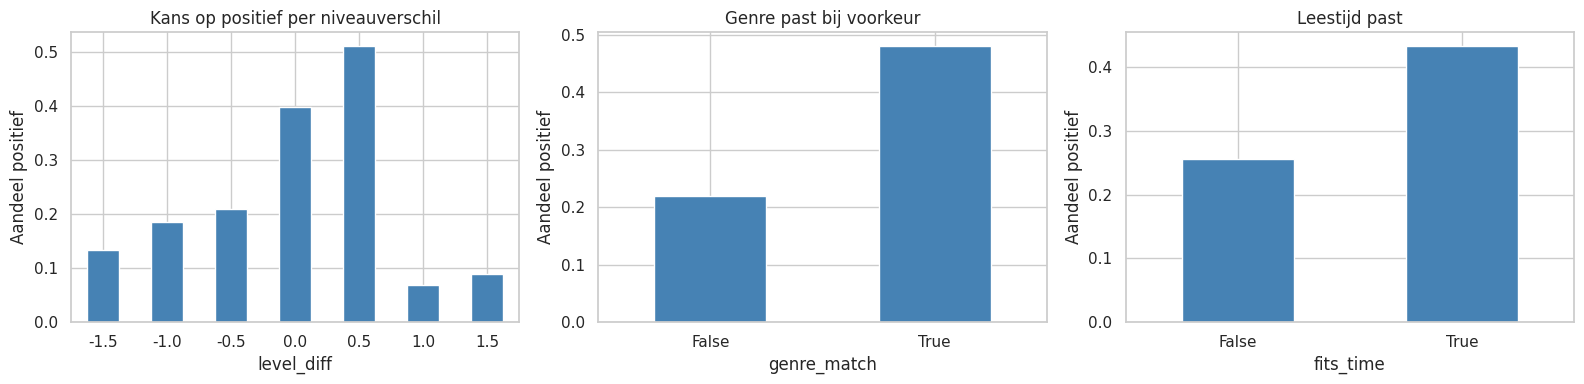

In [13]:
pairs = interactions.merge(students, on="student_id").merge(
    materials[["catalog_code", "level_num", "type", "genre", "reading_minutes", "avg_rating"]], on="catalog_code")
pairs["level_diff"] = pairs["level_num"] - pairs["reading_level_num"]
pairs["genre_match"] = pairs["genre"] == pairs["preferred_genre"]
pairs["fits_time"] = pairs["reading_minutes"] <= pairs["max_minutes"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pairs.groupby("level_diff")["positive"].mean().plot.bar(ax=axes[0], title="Kans op positief per niveauverschil", color="steelblue")
pairs.groupby("genre_match")["positive"].mean().plot.bar(ax=axes[1], title="Genre past bij voorkeur", color="steelblue")
pairs.groupby("fits_time")["positive"].mean().plot.bar(ax=axes[2], title="Leestijd past", color="steelblue")
for ax in axes:
    ax.set_ylabel("Aandeel positief")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "01_bivariate.png", dpi=120)
plt.show()

In [14]:
contingency = pd.crosstab(pairs["genre_match"], pairs["positive"])
chi2, p_value, _, _ = stats.chi2_contingency(contingency)
print(contingency)
print(f"Chi-kwadraat = {chi2:.1f}, p = {p_value:.2e}")

positive        0    1
genre_match           
False        1081  303
True          313  289
Chi-kwadraat = 135.5, p = 2.59e-31


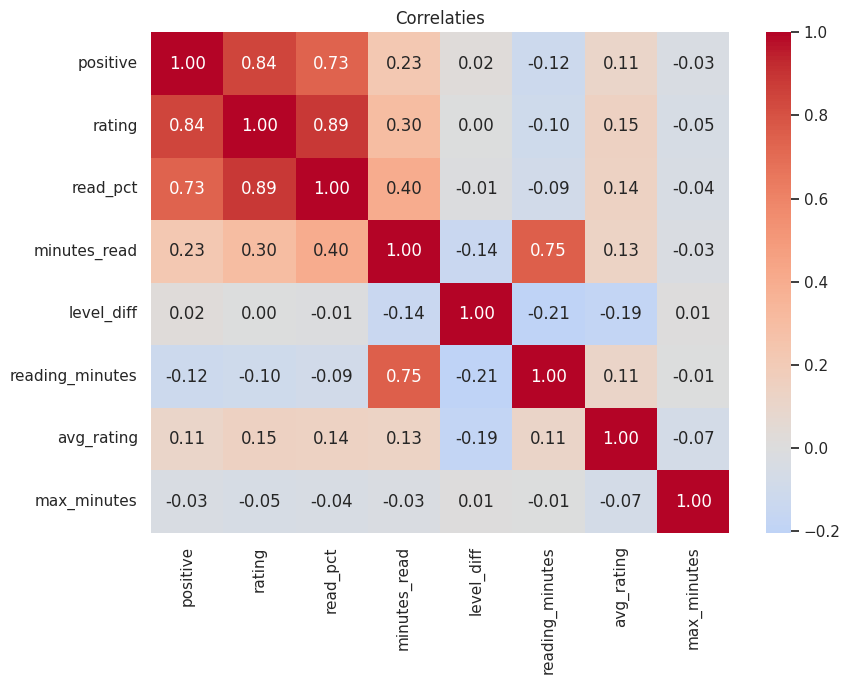

In [15]:
numeric_columns = ["positive", "rating", "read_pct", "minutes_read", "level_diff", "reading_minutes", "avg_rating", "max_minutes"]
plt.figure(figsize=(9, 7))
sns.heatmap(pairs[numeric_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaties")
plt.tight_layout()
plt.show()

## Conclusie

* Studenten reageren positief als het **niveau past** (gelijk of een half niveau hoger), als het **genre** en het
  **materiaaltype** bij hun voorkeur passen, als de **leestijd** binnen hun maximum valt en als het **onderwerp** bij hun
  interesses past. Materiaal dat veel te moeilijk is wordt bijna altijd afgewezen.
* Dat zijn precies de signalen die het model als kenmerken (features) krijgt.
* Let op: de interacties en een deel van de catalogus zijn **gesimuleerd** (`gegevensstatus`). Conclusies gelden voor
  deze dataset en moeten met echte studenten opnieuw getoetst worden.

De schone data staat nu in `data/processed/`.